# Learned Bloom Filters — 5. Results & Ablation

We plot all four designs on one **memory–FPR frontier**, then run the key
**negative-result ablation**: on *random* keys the oracle can't learn anything, so the
learned filters should **not** beat a plain Bloom filter. That proves the savings come
from genuine learnable structure.

In [1]:
# Download the URL dataset (~195k URLs, labelled malicious=1 / benign=0)
import os
import ssl
import urllib.request
import pandas as pd

DATA_URL = (
    "https://raw.githubusercontent.com/incertum/cyber-matrix-ai/"
    "master/Malicious-URL-Detection-Deep-Learning/data/url_data_mega_deep_learning.csv"
)

os.makedirs("data", exist_ok=True)

if not os.path.exists("data/url_data.csv"):
    # Relax TLS just for this one download (some Colab images lag on CA certs)
    ctx = ssl.create_default_context()
    ctx.check_hostname = False
    ctx.verify_mode = ssl.CERT_NONE
    request = urllib.request.Request(DATA_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(request, timeout=120, context=ctx) as response:
        with open("data/url_data.csv", "wb") as out:
            out.write(response.read())

print("Dataset ready.")

Dataset ready.


In [2]:
import numpy as np
import pandas as pd


def load_and_split(seed=42):
    """Set S = all malicious URLs (the things we store).
    The benign URLs are split into three groups:
      - train : teach the oracle what 'safe' looks like
      - val   : pick the threshold / settings
      - test  : untouched, used only to report the final false-positive rate
    """
    df = pd.read_csv("data/url_data.csv")
    df.columns = [c.strip() for c in df.columns]
    df = df.dropna().drop_duplicates("url").reset_index(drop=True)

    malicious = df[df.isMalicious == 1].url.tolist()
    benign = df[df.isMalicious == 0].url.sample(frac=1.0, random_state=seed).tolist()

    n = len(benign)
    neg_train = benign[: n // 2]
    neg_val = benign[n // 2 : 3 * n // 4]
    neg_test = benign[3 * n // 4 :]
    return malicious, neg_train, neg_val, neg_test

In [3]:
import math
import hashlib
import numpy as np


class BloomFilter:
    """A standard Bloom filter: m bits, k hash functions, never a false negative."""

    def __init__(self, m_bits, n_expected=None, k=None):
        self.m = int(max(1, m_bits))
        if k is None and n_expected:
            # Best number of hash functions for m bits and n keys is (m/n) * ln2
            k = round((self.m / n_expected) * math.log(2))
        self.k = int(max(1, k or 7))
        self.bits = np.zeros(self.m, dtype=np.uint8)

    def _positions(self, item):
        # Kirsch-Mitzenmacher trick: one MD5 -> two numbers -> k bit positions
        digest = hashlib.md5(item.encode("utf-8", "ignore")).digest()
        h1 = int.from_bytes(digest[:8], "little")
        h2 = int.from_bytes(digest[8:], "little") | 1
        return [(h1 + i * h2) % self.m for i in range(self.k)]

    def add(self, item):
        for p in self._positions(item):
            self.bits[p] = 1

    def add_all(self, items):
        for item in items:
            self.add(item)

    def __contains__(self, item):
        # All k bits set -> "probably in"; any bit is 0 -> "definitely not in"
        return all(self.bits[p] for p in self._positions(item))


def bf_theoretical_fpr(m, n, k):
    # Textbook false-positive rate of a Bloom filter
    return (1 - math.exp(-k * n / m)) ** k


def bf_bits_for_fpr(n, target_fpr):
    # Bits needed for n keys at a target FPR p:  m = -n*ln(p) / (ln2)^2
    if target_fpr <= 0:
        return 10 ** 9
    return math.ceil(-n * math.log(target_fpr) / (math.log(2) ** 2))

In [4]:
import re
import numpy as np
from sklearn.feature_extraction.text import HashingVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from scipy.sparse import hstack, vstack, csr_matrix

SUSPICIOUS = ["login", "secure", "account", "update", "verify", "bank",
              "confirm", "webscr", "signin", "paypal", "wp-", "admin",
              ".php", ".exe"]
SPECIAL = list("./-_?=&@%:#~+,;!$")


def lexical_features(url):
    """Hand-crafted numeric features describing one URL."""
    url = str(url)
    lower = url.lower()
    n = len(url) or 1

    # Shannon entropy = how 'random-looking' the characters are
    byte_vals = np.frombuffer(url.encode("utf-8", "ignore"), dtype=np.uint8)
    if byte_vals.size:
        _, counts = np.unique(byte_vals, return_counts=True)
        probs = counts / counts.sum()
        entropy = float(-(probs * np.log2(probs)).sum())
    else:
        entropy = 0.0

    feats = [
        len(url),
        len(lower.split("/")[0]),                          # host length
        sum(c.isdigit() for c in url) / n,
        sum(c.isalpha() for c in url) / n,
        entropy,
        url.count("."), url.count("/"), url.count("-"),
        url.count("="), url.count("?"), url.count("@"), url.count("%"),
        sum(lower.count(w) for w in SUSPICIOUS),           # suspicious keywords
        int(bool(re.search(r"\d+\.\d+\.\d+\.\d+", url))),   # contains an IP address?
        max((len(t) for t in re.split(r"[./\-_]", url)), default=0),
    ]
    feats += [url.count(c) / n for c in SPECIAL]           # ratio of each special char
    return feats


def train_oracle(malicious, neg_train, ngram_dim=4096):
    """Train the logistic-regression oracle. Returns (score_function, n_features).
    Features = lexical features + hashed character 3-to-5 grams (the hashing trick)."""
    hasher = HashingVectorizer(analyzer="char_wb", ngram_range=(3, 5),
                               n_features=ngram_dim, alternate_sign=False, norm="l2")

    def featurize(urls):
        lexical = np.array([lexical_features(u) for u in urls], dtype=np.float32)
        ngrams = hasher.transform(urls)
        return lexical, ngrams

    lex_pos, ng_pos = featurize(malicious)
    lex_neg, ng_neg = featurize(neg_train)

    # Scale the lexical features so the linear model trains smoothly
    scaler = StandardScaler().fit(np.vstack([lex_pos, lex_neg]))
    X_pos = hstack([csr_matrix(scaler.transform(lex_pos)), ng_pos]).tocsr()
    X_neg = hstack([csr_matrix(scaler.transform(lex_neg)), ng_neg]).tocsr()

    X = vstack([X_pos, X_neg]).tocsr()
    y = np.r_[np.ones(X_pos.shape[0]), np.zeros(X_neg.shape[0])]
    model = LogisticRegression(max_iter=3000, C=8.0, solver="liblinear").fit(X, y)
    n_features = X.shape[1]

    def score(urls):
        lexical, ngrams = featurize(urls)
        Xq = hstack([csr_matrix(scaler.transform(lexical)), ngrams]).tocsr()
        return model.predict_proba(Xq)[:, 1]

    return score, n_features

In [5]:
import numpy as np


def optimize_sandwiched(scores_pos, scores_neg, oracle_bits, target_fpr,
                        f0_grid=None, n_tau=200):
    """Find the smallest (fewest bits) learned filter that hits target_fpr.
    f0 is the initial-filter FPR (f0 = 1.0 means 'no initial filter', i.e. plain LBF).
    Returns the best configuration, or None if the target can't be reached."""
    sp = np.sort(scores_pos)
    sn = np.sort(scores_neg)
    n_pos = len(sp)

    if f0_grid is None:
        f0_grid = np.concatenate([[1.0], np.geomspace(0.05, 0.9, 12)])
    taus = np.quantile(sp, np.linspace(0.0, 0.99, n_tau))

    best = None
    for f0 in f0_grid:
        initial_bits = bf_bits_for_fpr(n_pos, f0) if f0 < 1.0 else 0
        for tau in taus:
            a = float(np.mean(sn >= tau))           # oracle's own false-positive rate
            below = 1.0 - a                          # fraction of negatives below tau
            c = int(np.sum(sp < tau))                # members the oracle would miss

            if f0 * a >= target_fpr:                 # oracle alone already too loose
                continue
            # Backup FPR needed so the whole thing lands on target_fpr
            backup_fpr = (target_fpr / f0 - a) / below if below > 0 else 0.0
            if backup_fpr <= 0:
                continue

            if c > 0 and backup_fpr < 1:
                backup_bits = bf_bits_for_fpr(c, min(backup_fpr, 0.999))
            else:
                backup_bits = 0

            total = initial_bits + oracle_bits + backup_bits
            if best is None or total < best["bits"]:
                best = {"bits": total, "tau": float(tau), "f0": float(f0),
                        "b": float(min(backup_fpr, 1.0)), "c": c}
    return best


def plbf_bits(scores_pos, scores_neg, oracle_bits, target_fpr, n_regions=8):
    """Partitioned LBF: split the score range into regions, give each region its own
    backup FPR by water-filling, return the total bits."""
    sp = np.sort(scores_pos)
    sn = np.sort(scores_neg)

    edges = np.quantile(sp, np.linspace(0, 1, n_regions + 1))
    edges[0] = -np.inf
    edges[-1] = np.inf

    g = np.histogram(sp, bins=edges)[0] / len(sp)        # member density per region
    h = np.histogram(sn, bins=edges)[0] / len(sn)        # non-member density per region
    ratio = np.where(h > 0, g / np.maximum(h, 1e-12), np.inf)

    # Water-filling: region FPR f_i = min(1, t * g_i / h_i); tune t so total FPR = target
    lo, hi = 0.0, 1e6
    for _ in range(60):
        t = (lo + hi) / 2
        f = np.minimum(1.0, t * ratio)
        if float(np.sum(h * f)) > target_fpr:
            hi = t
        else:
            lo = t
    f = np.minimum(1.0, lo * ratio)

    member_counts = np.histogram(sp, bins=edges)[0]
    bits = 0
    for count, region_fpr in zip(member_counts, f):
        if count > 0 and region_fpr < 1.0:
            bits += bf_bits_for_fpr(int(count), float(max(region_fpr, 1e-6)))
    return oracle_bits + bits

Train the oracle and draw the memory-vs-FPR frontier for all four designs.

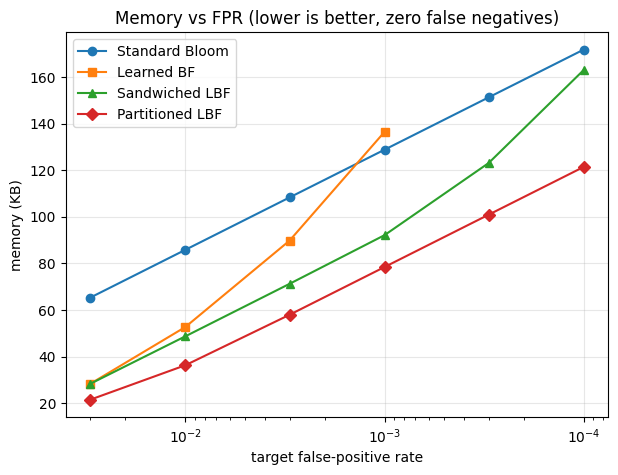

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

malicious, neg_train, neg_val, neg_test = load_and_split()
score, n_features = train_oracle(malicious, neg_train)
oracle_bits = (n_features + 1) * 8

scores_malicious = score(malicious)
scores_val = score(neg_val)

targets = [3e-2, 1e-2, 3e-3, 1e-3, 3e-4, 1e-4]


def to_kb(bits):
    return bits / 8 / 1024


bf_curve = []
lbf_curve = []
sand_curve = []
plbf_curve = []
for F in targets:
    bf_curve.append(to_kb(bf_bits_for_fpr(len(malicious), F)))
    lbf = optimize_sandwiched(scores_malicious, scores_val, oracle_bits, F, f0_grid=np.array([1.0]))
    sand = optimize_sandwiched(scores_malicious, scores_val, oracle_bits, F)
    lbf_curve.append(to_kb(lbf["bits"]) if lbf else np.nan)
    sand_curve.append(to_kb(sand["bits"]) if sand else np.nan)
    plbf_curve.append(to_kb(plbf_bits(scores_malicious, scores_val, oracle_bits, F)))

plt.figure(figsize=(7, 5))
plt.plot(targets, bf_curve, "o-", label="Standard Bloom")
plt.plot(targets, lbf_curve, "s-", label="Learned BF")
plt.plot(targets, sand_curve, "^-", label="Sandwiched LBF")
plt.plot(targets, plbf_curve, "D-", label="Partitioned LBF")
plt.xscale("log")
plt.gca().invert_xaxis()
plt.xlabel("target false-positive rate")
plt.ylabel("memory (KB)")
plt.title("Memory vs FPR (lower is better, zero false negatives)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Ablation — random keys have no structure to learn
If we repeat everything on random strings, the oracle should be no better than guessing, and the learned filter should lose to a plain Bloom filter.

In [7]:
# Random "url-like" strings: malicious and benign are now drawn the same way,
# so there is genuinely nothing to learn.
rng = np.random.default_rng(7)
alphabet = np.array(list("abcdefghijklmnopqrstuvwxyz0123456789./-_"))


def random_urls(count):
    urls = []
    for _ in range(count):
        length = int(rng.integers(15, 60))
        urls.append("".join(rng.choice(alphabet, length)))
    return urls


rand_keys = random_urls(len(malicious))
rand_train = random_urls(48000)
rand_val = random_urls(24000)

rand_score, rand_features = train_oracle(rand_keys, rand_train)
rand_bits = (rand_features + 1) * 8
rscores_keys = rand_score(rand_keys)
rscores_val = rand_score(rand_val)

rand_auc = roc_auc_score(np.r_[np.ones(len(rscores_keys)), np.zeros(len(rscores_val))],
                         np.r_[rscores_keys, rscores_val])
print("Random-key oracle AUC = %.3f  (about 0.5 means nothing to learn)" % rand_auc)
print()
print(" target | standard BF | partitioned | 'saving'")
for F in [3e-2, 1e-2, 1e-3, 1e-4]:
    bf_bits = bf_bits_for_fpr(len(rand_keys), F)
    plbf = plbf_bits(rscores_keys, rscores_val, rand_bits, F)
    print(" %.0e |   %6.1f    |   %6.1f    | %5.1f%%"
          % (F, to_kb(bf_bits), to_kb(plbf), (1 - plbf / bf_bits) * 100))

Random-key oracle AUC = 0.540  (about 0.5 means nothing to learn)

 target | standard BF | partitioned | 'saving'
 3e-02 |     65.4    |     69.2    |  -5.9%
 1e-02 |     85.8    |     89.7    |  -4.5%
 1e-03 |    128.8    |    132.6    |  -3.0%
 1e-04 |    171.7    |    175.5    |  -2.2%


## Conclusions
- **Partitioned LBF cuts memory ~29–67%** vs a standard Bloom filter at matched FPR (zero
  false negatives), e.g. **~39% at 0.1% FPR**, using only a ~4 KB oracle (AUC ≈ 0.97).
- **Plain LBF is *not* always better** — it degrades below the standard filter at low FPR
  and becomes infeasible; the Sandwiched and Partitioned designs are needed for stringent FPR.
- **Ablation:** on random keys the oracle is at chance (AUC ≈ 0.5) and the learned filter is
  a few percent *worse* than a plain Bloom filter — confirming the win needs learnable structure.

### Limitations & future work
- Single dataset (URLs); a neural oracle (char-CNN / GRU) could raise AUC at higher size cost.
- Static set only — a changing set needs retraining or rebuilding.
- Pure-Python build; a compiled hashing core would speed construction.